# 11: Replicação em uma terceira base (Tourism Monthly)

**Dissertação:** Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais: Desempenho, Robustez e Explicabilidade em Cenários de Dados Adversos
**Autora:** Luana Gomes de Souza, PPGI/UTFPR
**Etapa:** "prova dos nove": o mesmo protocolo dos notebooks 01 a 10 aplicado a uma base adicional, para verificar quais achados se sustentam em outro regime de dados.

### Base
Tourism Monthly Dataset, Monash Time Series Forecasting Repository (Zenodo, versão 3, DOI 10.5281/zenodo.4656096). São 366 séries mensais reais da competição de turismo (Athanasopoulos et al., 2011).

### Estrutura do notebook
| Etapa | Conteúdo | Protocolo de origem |
|---|---|---|
| 1 | Configuração e caracterização da base | NB10 (loader) |
| 1b | LIME corrigido no M4 (verificação antes de seguir) | NB09 |
| 2 | Desempenho em dados limpos | NB01 a 07 e NB10 |
| 3 | Cenários adversos | NB08 |
| 4 | Explicabilidade (SHAP e LIME) | NB09 |
| 5 | Estabilidade das explicações (Spearman e Jaccard top-k) | NB09 |
| 6 | Tabela de replicação (H1 a H4) | |

Resultados em `results/tourism/`. Cada etapa cara tem cache em CSV: com `FORCE_RERUN = False`, nada é recalculado se o arquivo já existe.

## Nota de limitações (diferenças de protocolo entre os notebooks existentes)

Esta nota registra diferenças encontradas nos notebooks 01 a 10 ao planejar esta replicação. **Os notebooks anteriores não foram alterados**; cada etapa deste notebook replica fielmente o protocolo do notebook de origem, para que os números sejam comparáveis com os já reportados.

**(B) Duas amostras piloto do M4.** Os notebooks 01 a 04b sorteiam as 200 séries com `rng.choice` sobre os IDs em ordem alfabética (`train_df['unique_id'].unique()` após `sort_values`), enquanto os notebooks 05 a 09 sorteiam sobre a ordem do arquivo (`src/m4_io.sample_pilot_ids` e `idx_sel` nos NB08 e NB09). As duas amostras têm apenas 3 séries em comum. Consequência: as tabelas do M4 que comparam modelos estatísticos (NB02 a 04b) com modelos de ML (NB05 a 07) usam conjuntos de séries diferentes. Para a hipótese H4 no M4, usamos `baseline_limpo_200series.csv` (NB08), em que todos os modelos foram avaliados nas mesmas 200 séries. Neste notebook, o Tourism usa uma única amostra para todas as etapas (regra dos NB05 a 09, ordem do arquivo).

**(C) Dois protocolos de avaliação.**

| Item | NB01 a 07 e NB10 (desempenho) | NB08 e NB09 (adversos e XAI) |
|---|---|---|
| Origens do rolling origin | `linspace(MIN_TRAIN, n - H, N_ORIGINS)` | os N_ORIGINS últimos blocos consecutivos de H |
| MAPE | máscara sobre valores reais não nulos | fallback para sMAPE quando mais de 50% dos valores reais são ~0 |
| Features de ML | lag_1 a lag_12, roll_mean e roll_std (janela 12), lag_season, lag_season2 | lag_1 a lag_12, roll_mean_3, roll_std_3, roll_mean_6, lag_season, lag_season2 |
| Random Forest | n_estimators=100, min_samples_leaf=2 | n_estimators=100, demais padrões do sklearn |
| Gradient Boosting | subsample=0,8 | subsample=1,0 (padrão) |
| Holt-Winters | aditivo ou multiplicativo por AIC | apenas aditivo, `remove_bias=True` |
| SARIMA automático | busca por AIC com limite de 300 s por série (NB04b) | grade completa sem limite (NB08, só na linha de base) |
| Agregação | mediana por série, depois mediana entre séries | mediana por série, depois mediana entre séries |

Decisão: a Etapa 2 usa o protocolo NB01 a 07 e NB10; as Etapas 3 a 5 usam o protocolo NB08 e NB09. Os números de desempenho das Etapas 2 e 3 não devem ser comparados diretamente entre si.

**(A) Correspondência de nomes no LIME do NB09.** A função `compute_lime` do NB09 associa cada termo do LIME a uma feature por substring (`if fn in fname`). Como `'lag_1'` está contido em `'lag_10 <= ...'`, a importância de lag_10, lag_11 e lag_12 é somada a lag_1, e a de lag_season2 é somada a lag_season (no cache `lime_importancias.csv` essas quatro colunas são sempre zero). Neste notebook o LIME é calculado em duas versões: **corrigida (oficial)**, com associação por índice via `exp.as_map()`, e **original**, mantida apenas para comparação.

**(D) Car Parts na explicabilidade.** Com 51 observações e o protocolo do NB09 (treino = série sem os últimos H), restam 9 linhas supervisionadas, abaixo do mínimo de 10 do NB09. Para o Car Parts, SHAP e LIME são calculados com a série inteira (27 linhas de treino) e os resultados são rotulados como **exploratórios**.

---
# Etapa 1: configuração e caracterização da base
## 1.1 Imports e configuração

In [1]:
import warnings, time, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from statsmodels.tsa.seasonal import STL

# ── Resolução de caminhos (mesma lógica do NB10: cwd em autopred/ ou notebooks/) ──
_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'notebooks').is_dir() and (_candidate / 'results').is_dir():
        PROJECT_ROOT = _candidate
        break
else:
    PROJECT_ROOT = _root

DATA_DIR = PROJECT_ROOT / 'data' / 'raw'

# Tourism: aceita o .tsf em data/raw/ ou em data/raw/tourism/
_tm_candidates = [
    DATA_DIR / 'tourism_monthly_dataset.tsf',
    DATA_DIR / 'tourism' / 'tourism_monthly_dataset.tsf',
]
TM_TSF_PATH = next((p for p in _tm_candidates if p.exists()), None)
if TM_TSF_PATH is None:
    raise FileNotFoundError('tourism_monthly_dataset.tsf não encontrado em:\n'
                            + '\n'.join(f'  {p}' for p in _tm_candidates))

# Car Parts (mesmos candidatos do NB10)
_cp_candidates = [
    DATA_DIR / 'car_parts' / 'car_parts_dataset_without_missing_values.tsf',
    DATA_DIR / 'car_parts_dataset_without_missing_values.tsf',
]
CP_TSF_PATH = next((p for p in _cp_candidates if p.exists()), None)
M4_TRAIN_PATH = DATA_DIR / 'Monthly-train.csv'

# ── Protocolo (idêntico aos notebooks 01 a 10, exceto H) ─────────────────────
SEED      = 42
# H = 24: horizonte oficial do Tourism Monthly no benchmark (Athanasopoulos et al., 2011;
# cabeçalho do .tsf: "@horizon 24"). No M4 Monthly e no Car Parts usamos H = 18.
# É a ÚNICA diferença de protocolo em relação às bases anteriores.
H         = 24
MIN_TRAIN = 24
N_ORIGINS = 3
SEASON    = 12

# ── Amostragem de séries (mesma lógica do piloto M4: 200 séries, SEED=42) ────
# Viabilidade das 366 séries completas: o Tourism tem séries de 91 a 333 obs
# (mediana 330). Pelos tempos medianos do M4 (RF ~0,34 s por janela, SARIMA
# heurístico ~0,1 s), rodar as 366 custa ~1,8x o piloto: estimativa de 15 a 30 min
# na Etapa 2 sem SARIMA auto, 2 a 4 h com SARIMA auto e ~1 h na Etapa 3.
# É viável; fica como análise de sensibilidade (RODAR_TODAS = True).
N_SERIES     = 200
RODAR_TODAS  = False          # True: usa as 366 séries (sensibilidade)
if RODAR_TODAS:
    N_SERIES = None

# ── Saídas: a sensibilidade com 366 séries vai para uma subpasta própria,
#    para não sobrescrever o cache do piloto de 200 séries ─────────────────────
RESULT_DIR = PROJECT_ROOT / 'results' / 'tourism'
if N_SERIES is None:
    RESULT_DIR = RESULT_DIR / 'sensibilidade_366'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Caches de bases anteriores (somente leitura)
M4_RESULTS_DIR = PROJECT_ROOT / 'results'
CP_RESULTS_DIR = PROJECT_ROOT / 'results' / 'car_parts'

# ── Cache: True força recálculo mesmo com CSV salvo ──────────────────────────
FORCE_RERUN = False

# Paleta por base (tons já usados no NB10)
BASE_COLORS = {'M4 Monthly': '#5B8DB8', 'Car Parts': '#E8834E', 'Tourism Monthly': '#6BAE75'}

print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'TM_TSF_PATH  = {TM_TSF_PATH}')
print(f'CP_TSF_PATH  = {CP_TSF_PATH}')
print(f'RESULT_DIR   = {RESULT_DIR}')
print(f'SEED={SEED} | H={H} | MIN_TRAIN={MIN_TRAIN} | N_ORIGINS={N_ORIGINS} | SEASON={SEASON}')
print(f'N_SERIES = {N_SERIES if N_SERIES else "TODAS"} | FORCE_RERUN = {FORCE_RERUN}')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
TM_TSF_PATH  = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw\tourism_monthly_dataset.tsf
CP_TSF_PATH  = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw\car_parts\car_parts_dataset_without_missing_values.tsf
RESULT_DIR   = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\tourism
SEED=42 | H=24 | MIN_TRAIN=24 | N_ORIGINS=3 | SEASON=12
N_SERIES = 200 | FORCE_RERUN = False


## 1.2 Carregador do formato TSF

Cópia fiel de `load_car_parts_tsf` (NB10), com uma única mudança: o parâmetro `encoding`. O cabeçalho do arquivo do Tourism contém o byte `0x96` (travessão em cp1252) num comentário, o que faz a leitura em UTF-8 falhar. As linhas de dados são ASCII, então ler em `latin-1` não altera nenhum valor.

Também adicionamos duas funções auxiliares: `read_tsf_header` (metadados `@...`) e `list_tsf_ids` (IDs na ordem do arquivo, equivalente a `src/m4_io.list_series_ids`, usada na amostragem).

In [2]:
def load_tsf(tsf_path, encoding='utf-8'):
    """
    Cópia de load_car_parts_tsf (NB10), com encoding parametrizável.

    Formato TSF: comentários '#', metadados '@', início dos dados em '@data',
    cada linha de dado: nome:timestamp:val1,val2,...
    Retorna DataFrame [unique_id, step, y] ordenado por série e passo.
    """
    records  = []
    in_data  = False

    with open(tsf_path, 'r', encoding=encoding) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if line.lower() == '@data':
                in_data = True
                continue
            if line.startswith('@'):
                continue
            if not in_data:
                continue

            parts = line.split(':')
            if len(parts) < 3:
                continue

            series_name = parts[0].strip()
            values_str  = parts[-1].strip()   # último campo = valores CSV

            try:
                values = [float(v) for v in values_str.split(',') if v.strip()]
            except ValueError:
                continue

            for step, val in enumerate(values, start=1):
                records.append({
                    'unique_id': series_name,
                    'step'     : step,
                    'y'        : val,
                })

    df = pd.DataFrame(records, columns=['unique_id', 'step', 'y'])
    return df.sort_values(['unique_id', 'step']).reset_index(drop=True)


def read_tsf_header(tsf_path, encoding='latin-1'):
    """Lê os metadados '@chave valor' antes de '@data' (ex.: @horizon, @missing)."""
    meta = {}
    with open(tsf_path, 'r', encoding=encoding) as f:
        for line in f:
            line = line.strip()
            if line.lower() == '@data':
                break
            if line.startswith('@') and not line.startswith('@attribute'):
                key, _, val = line[1:].partition(' ')
                meta[key] = val.strip()
    return meta


def list_tsf_ids(tsf_path, encoding='latin-1'):
    """IDs das séries na ordem do arquivo (equivalente a m4_io.list_series_ids)."""
    ids, in_data = [], False
    with open(tsf_path, 'r', encoding=encoding) as f:
        for line in f:
            line = line.strip()
            if line.lower() == '@data':
                in_data = True
                continue
            if in_data and line and not line.startswith('#'):
                ids.append(line.split(':')[0].strip())
    return ids


print('Funções de leitura TSF OK')

Funções de leitura TSF OK


## 1.3 Carga do Tourism Monthly e metadados do cabeçalho

In [3]:
tm_meta = read_tsf_header(TM_TSF_PATH)
print('Metadados do cabeçalho (.tsf):')
for k, v in tm_meta.items():
    print(f'  @{k:<12} {v}')

TM_MISSING     = tm_meta.get('missing')
TM_EQUALLENGTH = tm_meta.get('equallength')
TM_HORIZON     = int(tm_meta['horizon']) if 'horizon' in tm_meta else None
assert TM_HORIZON == H, f'H={H} difere do @horizon do arquivo ({TM_HORIZON})'

t0 = time.time()
df_tm_raw = load_tsf(TM_TSF_PATH, encoding='latin-1')
print(f'\nCarregado em {time.time() - t0:.2f}s')
print(f'Shape  : {df_tm_raw.shape}')
print(f'Séries : {df_tm_raw["unique_id"].nunique():,}')
print(f'NaN em y: {df_tm_raw["y"].isna().sum()}  (esperado 0, pois @missing = {TM_MISSING})')
print(f'Valores negativos: {(df_tm_raw["y"] < 0).sum()}')
print(df_tm_raw.head(5).to_string(index=False))

Metadados do cabeçalho (.tsf):
  @relation     Tourism
  @frequency    monthly
  @horizon      24
  @missing      false
  @equallength  false

Carregado em 0.07s
Shape  : (109280, 3)
Séries : 366
NaN em y: 0  (esperado 0, pois @missing = false)
Valores negativos: 0
unique_id  step         y
       T1     1 1149.8700
       T1     2 1053.8002
       T1     3 1388.8798
       T1     4 1783.3702
       T1     5 1921.0252


## 1.4 Seleção da amostra (mesma regra dos NB05 a 09)

`np.random.default_rng(SEED).choice(n, size=N_SERIES, replace=False)` sobre os IDs **na ordem do arquivo**. A ordem do sorteio é preservada (`posicao`), porque o subconjunto de 30 séries da explicabilidade (Etapa 4) é sorteado sobre essas posições, como no NB09.

Filtro de comprimento: `MIN_TRAIN + H = 48`. Também verificamos quantas séries têm as 3 janelas completas no protocolo do NB08 (`MIN_TRAIN + N_ORIGINS * H = 96`).

In [4]:
ids_arquivo = list_tsf_ids(TM_TSF_PATH)
assert len(ids_arquivo) == df_tm_raw['unique_id'].nunique()

if N_SERIES is None or N_SERIES >= len(ids_arquivo):
    idx_sel = np.arange(len(ids_arquivo))
else:
    rng_sel = np.random.default_rng(SEED)
    idx_sel = rng_sel.choice(len(ids_arquivo), size=N_SERIES, replace=False)

sample_ids = [ids_arquivo[i] for i in idx_sel]

# Séries em lista, na ordem do sorteio (como series_list nos NB08 e NB09)
_grp = {uid: g['y'].values.astype(float) for uid, g in df_tm_raw.groupby('unique_id')}
series_list = [_grp[uid] for uid in sample_ids]
lengths     = np.array([len(s) for s in series_list])

min_len    = MIN_TRAIN + H
min_len_08 = MIN_TRAIN + N_ORIGINS * H
print(f'Séries no arquivo  : {len(ids_arquivo)}')
print(f'Séries na amostra  : {len(sample_ids)}')
print(f'Comprimento >= MIN_TRAIN + H = {min_len}: {(lengths >= min_len).sum()} de {len(lengths)}')
print(f'3 janelas completas no protocolo NB08 (n >= {min_len_08}): {(lengths >= min_len_08).sum()} de {len(lengths)}')

df_amostra = pd.DataFrame({'posicao': range(len(sample_ids)), 'unique_id': sample_ids, 'n_obs': lengths})
df_amostra.to_csv(RESULT_DIR / 'amostra_series_tm.csv', index=False)
print(f'\nAmostra salva: amostra_series_tm.csv | primeiras: {sample_ids[:5]}')

Séries no arquivo  : 366
Séries na amostra  : 200
Comprimento >= MIN_TRAIN + H = 48: 200 de 200
3 janelas completas no protocolo NB08 (n >= 96): 199 de 200

Amostra salva: amostra_series_tm.csv | primeiras: ['T234', 'T325', 'T352', 'T31', 'T28']


## 1.5 Caracterização: comprimento, zeros, força de tendência e de sazonalidade

Para cada série, decomposição STL (período 12) e as medidas de Wang, Smith e Hyndman (2006), na forma de Hyndman e Athanasopoulos (*Forecasting: Principles and Practice*, 3a ed., seção 4.3):

$$F_T = \max\left(0,\ 1 - \frac{\mathrm{Var}(R_t)}{\mathrm{Var}(T_t + R_t)}\right) \qquad F_S = \max\left(0,\ 1 - \frac{\mathrm{Var}(R_t)}{\mathrm{Var}(S_t + R_t)}\right)$$

Valores próximos de 1 indicam tendência (ou sazonalidade) forte. Séries constantes (variância nula, comuns no Car Parts) recebem `NaN`.

Conjuntos caracterizados:
- **M4 Monthly**: as 200 séries do piloto dos NB05 a 09 (ordem do arquivo), parte de treino (`Monthly-train.csv`), como no NB09;
- **Car Parts**: as 2.674 séries (todas usadas no NB10);
- **Tourism Monthly**: a amostra de 200 séries e, para referência, as 366.

Cache por série em `caracterizacao_series_{base}.csv`.

In [5]:
def caracterizar_serie(y, season=SEASON):
    """Comprimento, proporção de zeros, CV e forças F_T e F_S via STL (Wang et al., 2006)."""
    y = np.asarray(y, dtype=float)
    out = {
        'n_obs'    : len(y),
        'zero_prop': float((y == 0).mean()),
        'cv'       : float(np.std(y) / np.mean(y)) if np.mean(y) != 0 else np.nan,
        'F_T'      : np.nan,
        'F_S'      : np.nan,
    }
    if len(y) < 2 * season or np.std(y) == 0:
        return out
    try:
        res = STL(y, period=season).fit()
        T, S, R = res.trend, res.seasonal, res.resid
        var_r = np.var(R)
        if np.var(T + R) > 0:
            out['F_T'] = float(max(0.0, 1 - var_r / np.var(T + R)))
        if np.var(S + R) > 0:
            out['F_S'] = float(max(0.0, 1 - var_r / np.var(S + R)))
    except Exception:
        pass
    return out


def caracterizar_base(series_dict, cache_file):
    """Aplica caracterizar_serie a {id: array}. Usa cache CSV se existir."""
    if cache_file.exists() and not FORCE_RERUN:
        df = pd.read_csv(cache_file)
        print(f'  cache: {cache_file.name} ({len(df)} séries)')
        return df
    t0 = time.time()
    rows = [{'unique_id': uid, **caracterizar_serie(y)} for uid, y in series_dict.items()]
    df = pd.DataFrame(rows)
    df.to_csv(cache_file, index=False)
    print(f'  calculado em {time.time() - t0:.1f}s, salvo: {cache_file.name} ({len(df)} séries)')
    return df


# Verificação com série sintética: sazonal pura + ruído pequeno => F_S alto, F_T baixo
_ex = 100 + 10 * np.sin(2 * np.pi * np.arange(120) / 12) + np.random.default_rng(SEED).normal(0, 1, 120)
print('Série sintética sazonal:', {k: round(v, 3) for k, v in caracterizar_serie(_ex).items()})

Série sintética sazonal: {'n_obs': 120, 'zero_prop': 0.0, 'cv': 0.072, 'F_T': 0.107, 'F_S': 0.994}


In [6]:
print('Tourism Monthly (amostra):')
car_tm = caracterizar_base(dict(zip(sample_ids, series_list)),
                           RESULT_DIR / 'caracterizacao_series_tm.csv')

print('Tourism Monthly (366 séries):')
car_tm_all = caracterizar_base(_grp, PROJECT_ROOT / 'results' / 'tourism' / 'caracterizacao_series_tm_366.csv')

print('Car Parts (2674 séries):')
_cp_cache = PROJECT_ROOT / 'results' / 'tourism' / 'caracterizacao_series_cp.csv'
if _cp_cache.exists() and not FORCE_RERUN:
    car_cp = caracterizar_base({}, _cp_cache)
else:
    df_cp_raw = load_tsf(CP_TSF_PATH, encoding='utf-8')
    car_cp = caracterizar_base(
        {uid: g['y'].values.astype(float) for uid, g in df_cp_raw.groupby('unique_id')}, _cp_cache)

print('M4 Monthly (200 séries do piloto NB05 a 09):')
_m4_cache = PROJECT_ROOT / 'results' / 'tourism' / 'caracterizacao_series_m4.csv'
if _m4_cache.exists() and not FORCE_RERUN:
    car_m4 = caracterizar_base({}, _m4_cache)
else:
    # Mesma seleção dos NB08 e NB09: índices de linha sobre a ordem do arquivo
    _m4_train_raw = pd.read_csv(M4_TRAIN_PATH, header=0, index_col=0)
    _m4_idx = np.random.default_rng(SEED).choice(len(_m4_train_raw), size=200, replace=False)
    _m4_dict = {_m4_train_raw.index[i]: _m4_train_raw.iloc[i].dropna().values.astype(float)
                for i in _m4_idx}
    car_m4 = caracterizar_base(_m4_dict, _m4_cache)
    del _m4_train_raw

Tourism Monthly (amostra):
  calculado em 0.7s, salvo: caracterizacao_series_tm.csv (200 séries)
Tourism Monthly (366 séries):
  calculado em 1.2s, salvo: caracterizacao_series_tm_366.csv (366 séries)
Car Parts (2674 séries):
  calculado em 1.8s, salvo: caracterizacao_series_cp.csv (2674 séries)
M4 Monthly (200 séries do piloto NB05 a 09):
  calculado em 0.5s, salvo: caracterizacao_series_m4.csv (200 séries)


## 1.6 Tabela comparativa entre as três bases

Medianas entre séries. O limiar de 0,5 em $F_S$ é apenas descritivo (sazonalidade moderada a forte).

In [7]:
def resumo_base(df, nome, n_total, h, missing, equallength):
    return {
        'Base'                   : nome,
        'Séries (total)'         : n_total,
        'Séries analisadas'      : len(df),
        'H'                      : h,
        '@missing'               : missing,
        '@equallength'           : equallength,
        'Comprimento mín.'       : int(df['n_obs'].min()),
        'Comprimento mediano'    : float(df['n_obs'].median()),
        'Comprimento máx.'       : int(df['n_obs'].max()),
        'Zeros (mediana, %)'     : round(100 * df['zero_prop'].median(), 1),
        'Séries com zeros (%)'   : round(100 * (df['zero_prop'] > 0).mean(), 1),
        'CV mediano'             : round(df['cv'].median(), 3),
        'F_T mediana'            : round(df['F_T'].median(), 3),
        'F_S mediana'            : round(df['F_S'].median(), 3),
        'F_S > 0,5 (%)'          : round(100 * (df['F_S'] > 0.5).mean(), 1),
        'STL indefinido (%)'     : round(100 * df['F_S'].isna().mean(), 1),
    }

cp_meta = read_tsf_header(CP_TSF_PATH) if CP_TSF_PATH else {}
tabela_bases = pd.DataFrame([
    resumo_base(car_m4, 'M4 Monthly', 48000, 18, 'n/a (CSV)', 'false'),
    resumo_base(car_cp, 'Car Parts', 2674, 18, cp_meta.get('missing'), cp_meta.get('equallength')),
    resumo_base(car_tm, 'Tourism Monthly', len(ids_arquivo), H, TM_MISSING, TM_EQUALLENGTH),
    resumo_base(car_tm_all, 'Tourism Monthly (366)', len(ids_arquivo), H, TM_MISSING, TM_EQUALLENGTH),
]).set_index('Base')

tabela_bases.to_csv(RESULT_DIR / 'caracterizacao_bases.csv')
print(tabela_bases.T.to_string())
print('\nSalvo: caracterizacao_bases.csv')

Base                 M4 Monthly Car Parts Tourism Monthly Tourism Monthly (366)
Séries (total)            48000      2674             366                   366
Séries analisadas           200      2674             200                   366
H                            18        18              24                    24
@missing              n/a (CSV)     false           false                 false
@equallength              false      true           false                 false
Comprimento mín.             66        51              91                    91
Comprimento mediano       198.0      51.0           332.0                 330.0
Comprimento máx.            918        51             333                   333
Zeros (mediana, %)          0.0      80.4             0.0                   0.0
Séries com zeros (%)        0.0     100.0            14.5                  16.7
CV mediano                0.298     2.365           0.681                 0.713
F_T mediana               0.977     0.29

### 1.6.1 Piso de ruído do $F_S$ (controle)

O STL sempre extrai algum componente sazonal, mesmo de ruído branco, e esse efeito é maior em séries curtas: com poucos ciclos (o Car Parts tem 51 obs, ou seja, ~4 anos) o suavizador sazonal absorve parte do ruído. Por isso $F_S$ não é comparável entre bases de comprimentos muito diferentes sem uma referência. Para cada base, simulamos 300 séries de ruído branco com o comprimento mediano da base e calculamos $F_S$ (piso). Reportamos o piso mediano, seu percentil 95 e a proporção de séries da base com $F_S$ acima do p95 do piso, que é a medida de sazonalidade **distinguível de ruído**.

In [8]:
N_SIM_PISO = 300
_piso_cache = RESULT_DIR / 'piso_ruido_fs.csv'

if _piso_cache.exists() and not FORCE_RERUN:
    df_piso = pd.read_csv(_piso_cache)
    print(f'cache: {_piso_cache.name}')
else:
    rng_piso = np.random.default_rng(SEED)
    _rows = []
    for nome, df_c in [('M4 Monthly', car_m4), ('Car Parts', car_cp),
                       ('Tourism Monthly', car_tm), ('Tourism Monthly (366)', car_tm_all)]:
        n_med = int(df_c['n_obs'].median())
        fs_sim = [caracterizar_serie(rng_piso.normal(0, 1, n_med))['F_S'] for _ in range(N_SIM_PISO)]
        _rows.append({'Base': nome, 'n_mediano': n_med,
                      'F_S piso (mediana)': float(np.median(fs_sim)),
                      'F_S piso (p95)': float(np.percentile(fs_sim, 95))})
    df_piso = pd.DataFrame(_rows)
    df_piso.to_csv(_piso_cache, index=False)

df_piso = df_piso.set_index('Base')
_car_por_base = {'M4 Monthly': car_m4, 'Car Parts': car_cp,
                 'Tourism Monthly': car_tm, 'Tourism Monthly (366)': car_tm_all}
tabela_bases['F_S piso ruído (mediana)'] = df_piso['F_S piso (mediana)'].round(3)
tabela_bases['F_S piso ruído (p95)']     = df_piso['F_S piso (p95)'].round(3)
tabela_bases['F_S acima do piso p95 (%)'] = pd.Series({
    b: round(100 * (_car_por_base[b]['F_S'] > df_piso.loc[b, 'F_S piso (p95)']).mean(), 1)
    for b in tabela_bases.index})

tabela_bases.to_csv(RESULT_DIR / 'caracterizacao_bases.csv')
print(tabela_bases[['Comprimento mediano', 'F_S mediana', 'F_S piso ruído (mediana)',
                    'F_S piso ruído (p95)', 'F_S acima do piso p95 (%)']].to_string())
print('\ncaracterizacao_bases.csv atualizado com o piso de ruído')

                       Comprimento mediano  F_S mediana  F_S piso ruído (mediana)  F_S piso ruído (p95)  F_S acima do piso p95 (%)
Base                                                                                                                              
M4 Monthly                           198.0        0.506                     0.373                 0.456                       56.5
Car Parts                             51.0        0.585                     0.588                 0.725                       18.0
Tourism Monthly                      332.0        0.838                     0.365                 0.424                       98.5
Tourism Monthly (366)                330.0        0.859                     0.361                 0.424                       99.2

caracterizacao_bases.csv atualizado com o piso de ruído


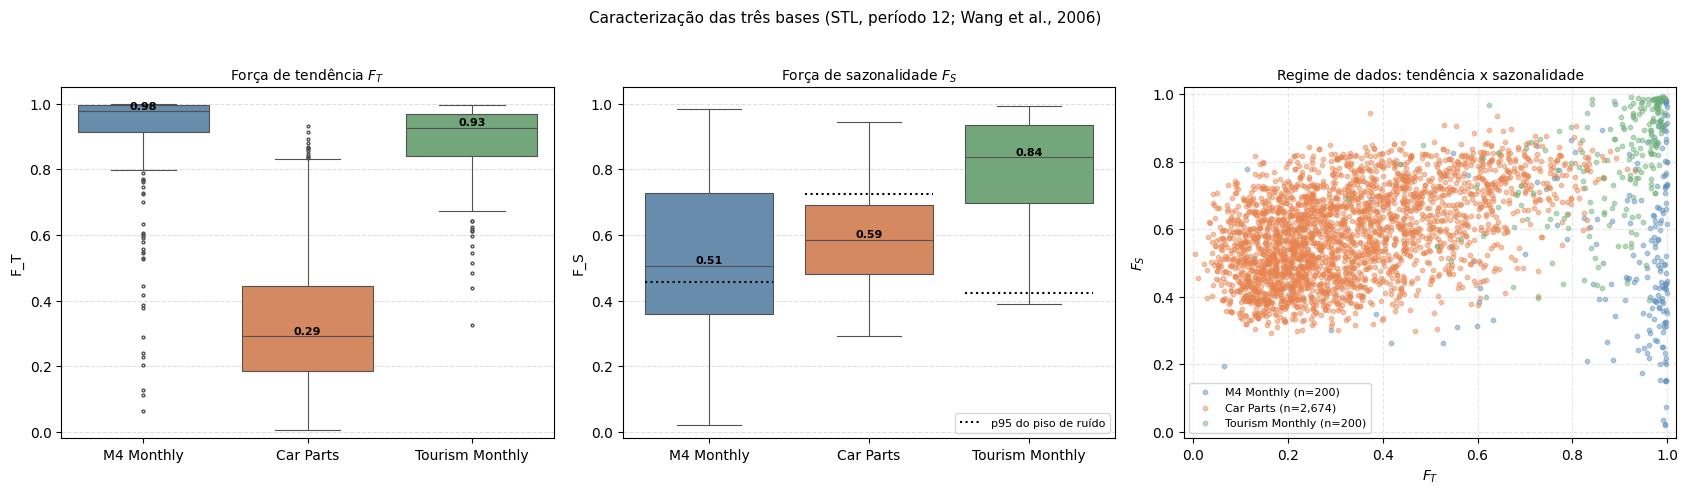

Figura salva: fig_caracterizacao_bases.png


In [9]:
# ── Figura: distribuição de F_T e F_S por base + dispersão F_T x F_S ──────────
_car = pd.concat([
    car_m4.assign(base='M4 Monthly'),
    car_cp.assign(base='Car Parts'),
    car_tm.assign(base='Tourism Monthly'),
], ignore_index=True)
_ordem = list(BASE_COLORS.keys())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col, titulo in zip(axes[:2], ['F_T', 'F_S'], ['Força de tendência $F_T$', 'Força de sazonalidade $F_S$']):
    sns.boxplot(data=_car, x='base', y=col, order=_ordem, palette=BASE_COLORS,
                ax=ax, fliersize=2, linewidth=0.8)
    for i, b in enumerate(_ordem):
        med = _car.loc[_car['base'] == b, col].median()
        ax.text(i, med, f'{med:.2f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
        if col == 'F_S':
            ax.hlines(df_piso.loc[b, 'F_S piso (p95)'], i - 0.4, i + 0.4, colors='black',
                      linestyles=':', linewidth=1.5, label='p95 do piso de ruído' if i == 0 else None)
    if col == 'F_S':
        ax.legend(fontsize=8, loc='lower right')
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylim(-0.02, 1.05)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

for b in _ordem:
    sub = _car[_car['base'] == b]
    axes[2].scatter(sub['F_T'], sub['F_S'], s=10, alpha=0.45, color=BASE_COLORS[b],
                    label=f'{b} (n={sub["F_S"].notna().sum():,})')
axes[2].set_xlabel('$F_T$'); axes[2].set_ylabel('$F_S$')
axes[2].set_xlim(-0.02, 1.02); axes[2].set_ylim(-0.02, 1.02)
axes[2].set_title('Regime de dados: tendência x sazonalidade', fontsize=10)
axes[2].legend(fontsize=8, loc='lower left')
axes[2].grid(linestyle='--', alpha=0.3)

plt.suptitle('Caracterização das três bases (STL, período 12; Wang et al., 2006)', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_caracterizacao_bases.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_caracterizacao_bases.png')

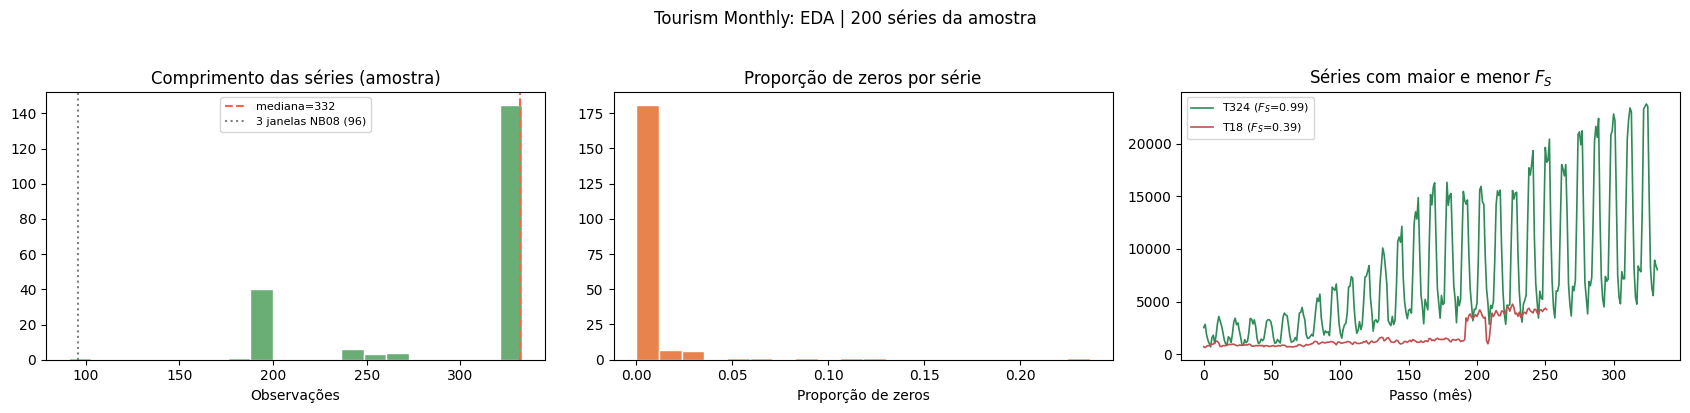

Figura salva: fig_eda_tourism.png


In [10]:
# ── Figura: EDA do Tourism (comprimentos, zeros, exemplos com F_S alto e baixo) ──
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(car_tm['n_obs'], bins=20, color=BASE_COLORS['Tourism Monthly'], edgecolor='white')
axes[0].axvline(car_tm['n_obs'].median(), color='tomato', linestyle='--',
                label=f'mediana={car_tm["n_obs"].median():.0f}')
axes[0].axvline(MIN_TRAIN + N_ORIGINS * H, color='gray', linestyle=':',
                label=f'3 janelas NB08 ({MIN_TRAIN + N_ORIGINS * H})')
axes[0].set_title('Comprimento das séries (amostra)'); axes[0].set_xlabel('Observações'); axes[0].legend(fontsize=8)

axes[1].hist(car_tm['zero_prop'], bins=20, color='#E8834E', edgecolor='white')
axes[1].set_title('Proporção de zeros por série'); axes[1].set_xlabel('Proporção de zeros')

_hi = car_tm.sort_values('F_S', ascending=False).iloc[0]['unique_id']
_lo = car_tm.sort_values('F_S').iloc[0]['unique_id']
for uid, cor in [(_hi, '#2E8B57'), (_lo, '#C05050')]:
    fs = car_tm.set_index('unique_id').loc[uid, 'F_S']
    axes[2].plot(_grp[uid], color=cor, linewidth=1.2, label=f'{uid} ($F_S$={fs:.2f})')
axes[2].set_title('Séries com maior e menor $F_S$'); axes[2].set_xlabel('Passo (mês)'); axes[2].legend(fontsize=8)

plt.suptitle(f'Tourism Monthly: EDA | {len(sample_ids)} séries da amostra', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_eda_tourism.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_eda_tourism.png')

## 1.7 Registro da Etapa 1

In [11]:
log_etapa1 = {
    'timestamp'        : datetime.now().isoformat(),
    'notebook'         : '11_replicacao_tourism',
    'etapa'            : 1,
    'dataset'          : 'Tourism Monthly (Monash, Zenodo v3, DOI 10.5281/zenodo.4656096)',
    'tsf_meta'         : tm_meta,
    'n_series_arquivo' : len(ids_arquivo),
    'n_series_amostra' : len(sample_ids),
    'seed'             : SEED, 'H': H, 'min_train': MIN_TRAIN, 'n_origins': N_ORIGINS, 'season': SEASON,
    'nota_H'           : 'H=24 (benchmark Tourism); M4 e Car Parts usam H=18',
    'caracterizacao'   : tabela_bases.reset_index().to_dict(orient='records'),
}
with open(RESULT_DIR / 'run_log_tm_etapa1.json', 'w', encoding='utf-8') as f:
    json.dump(log_etapa1, f, indent=2, ensure_ascii=False, default=str)
print('Salvo: run_log_tm_etapa1.json')

Salvo: run_log_tm_etapa1.json


---
# Etapa 1b: LIME corrigido no M4 (limpo e com ruído σ=30%)

Verificação pedida antes das Etapas 2 a 6. O LIME limpo corrigido do M4 foi regenerado no próprio NB09 (`results/explicabilidade/lime_importancias.csv`; versão anterior em `results/explicabilidade_original_bugado/`). Aqui calculamos o LIME **com ruído σ=30%** nas mesmas 30 séries, reproduzindo exatamente a perturbação do NB09 (seção 9: `default_rng(SEED)` avançando série a série), para ter SHAP e LIME nas duas condições.

As funções de explicabilidade abaixo são cópias fiéis do NB09, com duas mudanças explícitas:
- `h` e `min_train` viram parâmetros de `train_models_for_series` (no NB09 eram as globais `H=18` e `MIN_TRAIN=24`; aqui o `H` global é 24, do Tourism);
- `compute_lime` usa a associação corrigida por índice (`exp.as_map()[1]`); `compute_lime_original` mantém a associação por substring, **apenas para comparação**.

Arquivos desta etapa usam o prefixo `xai_m4_` em `results/tourism/`.

## 1b.1 Funções de explicabilidade (cópia do NB09)

In [12]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr, pearsonr
import shap
from lime.lime_tabular import LimeTabularExplainer

N_LAGS     = 12
N_EXPL     = 30
MODELOS_XAI = ['RandomForest', 'GradientBoosting', 'SVR']
ALGO_COLORS_XAI = {'RandomForest': '#F44336', 'GradientBoosting': '#9C27B0', 'SVR': '#795548'}


def build_features_xai(series, n_lags=N_LAGS, season=SEASON):
    """Cópia de build_features do NB09 (features do protocolo NB08 e NB09)."""
    df = pd.DataFrame({'y': series})
    feat_cols = []
    for lag in range(1, n_lags + 1):
        col = f'lag_{lag}'
        df[col] = df['y'].shift(lag)
        feat_cols.append(col)
    for w, name in [(3, 'roll_mean_3'), (3, 'roll_std_3'), (6, 'roll_mean_6')]:
        if 'std' in name:
            df[name] = df['y'].shift(1).rolling(w).std()
        else:
            df[name] = df['y'].shift(1).rolling(w).mean()
        feat_cols.append(name)
    df['lag_season']  = df['y'].shift(season)
    df['lag_season2'] = df['y'].shift(season * 2)
    feat_cols += ['lag_season', 'lag_season2']
    df.dropna(inplace=True)
    return df[feat_cols].values, df['y'].values, feat_cols


FEATURE_NAMES = [f'lag_{i}' for i in range(1, N_LAGS + 1)] + \
                ['roll_mean_3', 'roll_std_3', 'roll_mean_6', 'lag_season', 'lag_season2']
N_FEATURES = len(FEATURE_NAMES)


def train_models_for_series(series, h, min_train=MIN_TRAIN, usar_serie_inteira=False):
    """
    Cópia de train_models_for_series do NB09, com h e min_train explícitos.
    usar_serie_inteira=True: exceção documentada para o Car Parts (ver nota D).
    """
    if usar_serie_inteira:
        train = series
    else:
        train = series[:-h] if len(series) > min_train + h else series
    X, y, feat_cols = build_features_xai(train)
    if len(X) < 10:
        return None

    fitted = {}
    rf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    rf.fit(X, y)
    fitted['RandomForest'] = {'model': rf, 'X': X, 'y': y, 'scaler_X': None, 'scaler_y': None}

    gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=SEED)
    gb.fit(X, y)
    fitted['GradientBoosting'] = {'model': gb, 'X': X, 'y': y, 'scaler_X': None, 'scaler_y': None}

    scaler_X, scaler_y = StandardScaler(), StandardScaler()
    Xs = scaler_X.fit_transform(X)
    ys = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()
    svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    svr.fit(Xs, ys)
    fitted['SVR'] = {'model': svr, 'X': X, 'y': y, 'scaler_X': scaler_X, 'scaler_y': scaler_y}
    return fitted


def compute_shap(fitted_dict, model_name, max_background=50):
    """Cópia de compute_shap do NB09 (TreeExplainer para árvores, KernelExplainer para SVR)."""
    m, X, sX = fitted_dict['model'], fitted_dict['X'], fitted_dict['scaler_X']
    X_input = sX.transform(X) if sX is not None else X
    bg_size = min(max_background, len(X_input))
    rng_bg  = np.random.default_rng(SEED)
    bg_idx  = rng_bg.choice(len(X_input), size=bg_size, replace=False)
    background = X_input[bg_idx]
    try:
        if model_name in ('RandomForest', 'GradientBoosting'):
            shap_values = shap.TreeExplainer(m).shap_values(X_input)
        else:
            explainer   = shap.KernelExplainer(m.predict, background)
            sample_idx  = rng_bg.choice(len(X_input), size=min(30, len(X_input)), replace=False)
            shap_values = explainer.shap_values(X_input[sample_idx], nsamples=50)
        return np.abs(shap_values).mean(axis=0)
    except Exception:
        return np.full(N_FEATURES, np.nan)


def _lime_explain(fitted_dict, feature_names, num_samples=200):
    """Parte comum do compute_lime do NB09: explica o último ponto de treino."""
    m, X = fitted_dict['model'], fitted_dict['X']
    sX, sy = fitted_dict['scaler_X'], fitted_dict['scaler_y']
    X_input = sX.transform(X) if sX is not None else X

    def predict_fn(x):
        if sy is not None:
            return sy.inverse_transform(m.predict(x).reshape(-1, 1)).ravel()
        return m.predict(x)

    explainer = LimeTabularExplainer(training_data=X_input, feature_names=feature_names,
                                     mode='regression', random_state=SEED, verbose=False)
    return explainer.explain_instance(X_input[-1], predict_fn,
                                      num_features=len(feature_names), num_samples=num_samples)


def compute_lime(fitted_dict, model_name, feature_names):
    """LIME CORRIGIDO (oficial): associação por índice via exp.as_map()[1]."""
    try:
        exp = _lime_explain(fitted_dict, feature_names)
        coefs = np.zeros(len(feature_names))
        for j, val in exp.as_map()[1]:
            coefs[j] = abs(val)
        return coefs
    except Exception:
        return np.full(len(feature_names), np.nan)


def compute_lime_original(fitted_dict, model_name, feature_names):
    """LIME ORIGINAL do NB09 (associação por substring), mantido só para comparação."""
    try:
        exp = _lime_explain(fitted_dict, feature_names)
        coefs = np.zeros(len(feature_names))
        for fname, val in dict(exp.as_list()).items():
            for j, fn in enumerate(feature_names):
                if fn in fname:
                    coefs[j] += abs(val)
                    break
        return coefs
    except Exception:
        return np.full(len(feature_names), np.nan)


def perturb_noise_xai(series, sigma_frac, rng):
    """Cópia de perturb_noise do NB09 (idêntica à do NB08)."""
    return series + rng.normal(0, np.std(series) * sigma_frac, size=len(series))


def importancias_por_serie(fitted_list, fn, nome_arquivo):
    """Aplica fn (compute_shap/compute_lime/...) a cada série e modelo, com cache CSV."""
    arq = RESULT_DIR / nome_arquivo
    if arq.exists() and not FORCE_RERUN:
        print(f'  cache: {arq.name}')
        return pd.read_csv(arq)
    t0, rows = time.time(), []
    for i, fd in enumerate(fitted_list):
        if fd is None:
            continue
        for mn in MODELOS_XAI:
            imp = fn(fd[mn], mn) if fn is compute_shap else fn(fd[mn], mn, FEATURE_NAMES)
            rows.append({'serie': i, 'modelo': mn, **dict(zip(FEATURE_NAMES, imp))})
    df = pd.DataFrame(rows)
    df.to_csv(arq, index=False)
    print(f'  {arq.name} calculado em {time.time() - t0:.0f}s')
    return df


def resumo_xai(df_s, df_l, modelo):
    """Pearson SHAP x LIME (normalização pelo máximo, como na Fig. 4 do NB09), top-10 e posições."""
    s = df_s[df_s['modelo'] == modelo][FEATURE_NAMES].mean()
    l = df_l[df_l['modelo'] == modelo][FEATURE_NAMES].mean()
    r = np.corrcoef((s / (s.max() + 1e-10)).values, (l / (l.max() + 1e-10)).values)[0, 1]
    rs = s.rank(ascending=False, method='min').astype(int)
    rl = l.rank(ascending=False, method='min').astype(int)
    return {'modelo': modelo, 'pearson': round(r, 3),
            'pos_lag_season_SHAP': rs['lag_season'], 'pos_lag_season_LIME': rl['lag_season'],
            'pos_lag_season2_SHAP': rs['lag_season2'], 'pos_lag_season2_LIME': rl['lag_season2'],
            'top10_SHAP': ', '.join(s.sort_values(ascending=False).index[:10]),
            'top10_LIME': ', '.join(l.sort_values(ascending=False).index[:10])}


print(f'Funções XAI OK | {N_FEATURES} features: {FEATURE_NAMES}')

Funções XAI OK | 17 features: ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'roll_mean_3', 'roll_std_3', 'roll_mean_6', 'lag_season', 'lag_season2']


## 1b.2 Séries do M4 e perturbação idênticas às do NB09

In [13]:
H_M4 = 18   # horizonte do M4 (NB09)

_m4_train_raw = pd.read_csv(M4_TRAIN_PATH, header=0, index_col=0)
_idx_m4 = np.random.default_rng(SEED).choice(len(_m4_train_raw), size=200, replace=False)
m4_series_list = [_m4_train_raw.iloc[i].dropna().values.astype(float) for i in _idx_m4]
del _m4_train_raw

# Subconjunto de 30 séries: mesma regra do NB09 (semente SEED + 1 sobre as posições)
m4_expl_idx    = np.random.default_rng(SEED + 1).choice(200, size=N_EXPL, replace=False)
m4_expl_series = [m4_series_list[i] for i in m4_expl_idx]

# Perturbação: mesmo gerador sequencial da seção 9 do NB09
rng_pert = np.random.default_rng(SEED)
m4_expl_pert = [perturb_noise_xai(s, sigma_frac=0.30, rng=rng_pert) for s in m4_expl_series]

t0 = time.time()
m4_fit_clean = [train_models_for_series(s, h=H_M4) for s in m4_expl_series]
m4_fit_pert  = [train_models_for_series(s, h=H_M4) for s in m4_expl_pert]
print(f'Modelos treinados em {time.time() - t0:.0f}s | válidas: '
      f'{sum(f is not None for f in m4_fit_clean)} limpas, {sum(f is not None for f in m4_fit_pert)} com ruído')

Modelos treinados em 9s | válidas: 30 limpas, 30 com ruído


In [14]:
# Verificação de reprodutibilidade: o SHAP das árvores (determinístico) recalculado
# sobre as séries com ruído deve coincidir com shap_pert_* do cache do NB09.
_stab = pd.read_csv(M4_RESULTS_DIR / 'explicabilidade' / 'shap_estabilidade_adversa.csv')
_dev = []
for i in range(3):
    for mn in ['RandomForest', 'GradientBoosting']:
        rec = compute_shap(m4_fit_pert[i][mn], mn)
        cac = _stab[(_stab['serie'] == i) & (_stab['modelo'] == mn)][[f'shap_pert_{f}' for f in FEATURE_NAMES]].values[0]
        _dev.append(np.max(np.abs(rec - cac) / (np.abs(cac) + 1e-9)))
print(f'Desvio relativo máximo SHAP recalculado x cache NB09 (3 séries, árvores): {max(_dev):.2e}')
print('Reprodução exata' if max(_dev) < 1e-6 else 'ATENÇÃO: perturbação ou modelos não coincidem com o NB09')

Desvio relativo máximo SHAP recalculado x cache NB09 (3 séries, árvores): 1.79e-16
Reprodução exata


## 1b.3 LIME com ruído σ=30% (corrigido e original)

SHAP limpo e com ruído vêm do cache do NB09 (`shap_importancias.csv` e `shap_estabilidade_adversa.csv`); o SHAP do SVR usa KernelExplainer, cuja amostragem interna não é semeada no NB09, então não o recalculamos. LIME limpo corrigido: NB09 regenerado. LIME com ruído: calculado aqui.

In [15]:
print('LIME com ruído σ=30%, corrigido:')
xai_m4_lime_pert = importancias_por_serie(m4_fit_pert, compute_lime, 'xai_m4_lime_corrigido_ruido30.csv')
print('LIME com ruído σ=30%, original (comparação):')
xai_m4_lime_pert_orig = importancias_por_serie(m4_fit_pert, compute_lime_original, 'xai_m4_lime_original_ruido30.csv')

# Demais insumos (cache do NB09)
_expl = M4_RESULTS_DIR / 'explicabilidade'
xai_m4_shap_clean = pd.read_csv(_expl / 'shap_importancias.csv')
xai_m4_lime_clean = pd.read_csv(_expl / 'lime_importancias.csv')                       # corrigido
xai_m4_lime_clean_orig = pd.read_csv(M4_RESULTS_DIR / 'explicabilidade_original_bugado' / 'lime_importancias.csv')
xai_m4_shap_pert = _stab[['serie', 'modelo']].copy()
for f in FEATURE_NAMES:
    xai_m4_shap_pert[f] = _stab[f'shap_pert_{f}']
xai_m4_shap_pert.to_csv(RESULT_DIR / 'xai_m4_shap_ruido30.csv', index=False)

# Garantia: o LIME limpo carregado é o corrigido (lag_10 deixa de ser sempre zero)
assert xai_m4_lime_clean['lag_10'].abs().sum() > 0, 'lime_importancias.csv ainda é a versão antiga: rode o NB09 corrigido'
print('Insumos carregados.')

LIME com ruído σ=30%, corrigido:
  xai_m4_lime_corrigido_ruido30.csv calculado em 2s
LIME com ruído σ=30%, original (comparação):
  xai_m4_lime_original_ruido30.csv calculado em 2s
Insumos carregados.


## 1b.4 Resultado: Pearson SHAP x LIME, top-10 e posição dos lags sazonais

In [16]:
_linhas = []
for cond, df_s, df_l, versao in [
    ('limpo',      xai_m4_shap_clean, xai_m4_lime_clean,      'corrigido'),
    ('limpo',      xai_m4_shap_clean, xai_m4_lime_clean_orig, 'original'),
    ('ruído 30%',  xai_m4_shap_pert,  xai_m4_lime_pert,       'corrigido'),
    ('ruído 30%',  xai_m4_shap_pert,  xai_m4_lime_pert_orig,  'original'),
]:
    for mn in MODELOS_XAI:
        _linhas.append({'base': 'M4', 'condicao': cond, 'lime': versao, **resumo_xai(df_s, df_l, mn)})

xai_m4_resumo = pd.DataFrame(_linhas)
xai_m4_resumo.to_csv(RESULT_DIR / 'xai_m4_resumo_etapa1b.csv', index=False)

_cols = ['condicao', 'lime', 'modelo', 'pearson', 'pos_lag_season_SHAP', 'pos_lag_season_LIME',
         'pos_lag_season2_SHAP', 'pos_lag_season2_LIME']
print('Pearson SHAP x LIME e posições (1 = mais importante, entre 17 features):\n')
print(xai_m4_resumo[_cols].to_string(index=False))
print('\nSalvo: xai_m4_resumo_etapa1b.csv')

Pearson SHAP x LIME e posições (1 = mais importante, entre 17 features):

 condicao      lime           modelo  pearson  pos_lag_season_SHAP  pos_lag_season_LIME  pos_lag_season2_SHAP  pos_lag_season2_LIME
    limpo corrigido     RandomForest    0.992                    7                    8                     5                     5
    limpo corrigido GradientBoosting    0.994                    8                   10                     6                     6
    limpo corrigido              SVR    0.980                    8                   11                     6                     8
    limpo  original     RandomForest    0.959                    7                    3                     5                    14
    limpo  original GradientBoosting    0.952                    8                    3                     6                    14
    limpo  original              SVR    0.908                    8                    3                     6                    14
ru

In [17]:
# Top-10 (versão oficial: LIME corrigido)
for cond in ['limpo', 'ruído 30%']:
    print(f'=== M4, {cond} ===')
    sub = xai_m4_resumo[(xai_m4_resumo['condicao'] == cond) & (xai_m4_resumo['lime'] == 'corrigido')]
    for _, r in sub.iterrows():
        print(f"{r['modelo']:<17} SHAP: {r['top10_SHAP']}")
        print(f"{'':<17} LIME: {r['top10_LIME']}")
    print()

=== M4, limpo ===
RandomForest      SHAP: lag_1, roll_mean_3, lag_3, roll_mean_6, lag_season2, lag_2, lag_season, lag_12, lag_4, lag_5
                  LIME: lag_1, roll_mean_3, roll_mean_6, lag_3, lag_season2, lag_2, lag_12, lag_season, lag_9, lag_4
GradientBoosting  SHAP: lag_1, roll_mean_3, lag_3, roll_mean_6, lag_2, lag_season2, lag_11, lag_season, lag_5, lag_12
                  LIME: lag_1, roll_mean_3, roll_mean_6, lag_2, lag_3, lag_season2, lag_11, lag_8, lag_12, lag_season
SVR               SHAP: lag_1, roll_mean_3, lag_2, roll_mean_6, lag_3, lag_season2, lag_4, lag_season, lag_12, lag_5
                  LIME: lag_1, roll_mean_3, roll_mean_6, lag_3, lag_2, lag_7, lag_4, lag_season2, lag_5, lag_12

=== M4, ruído 30% ===
RandomForest      SHAP: roll_mean_6, roll_mean_3, lag_1, lag_2, lag_3, lag_season2, lag_6, lag_4, lag_5, lag_7
                  LIME: roll_mean_6, lag_1, roll_mean_3, lag_4, lag_8, lag_2, lag_3, lag_season2, lag_7, lag_5
GradientBoosting  SHAP: lag_1, roll_me

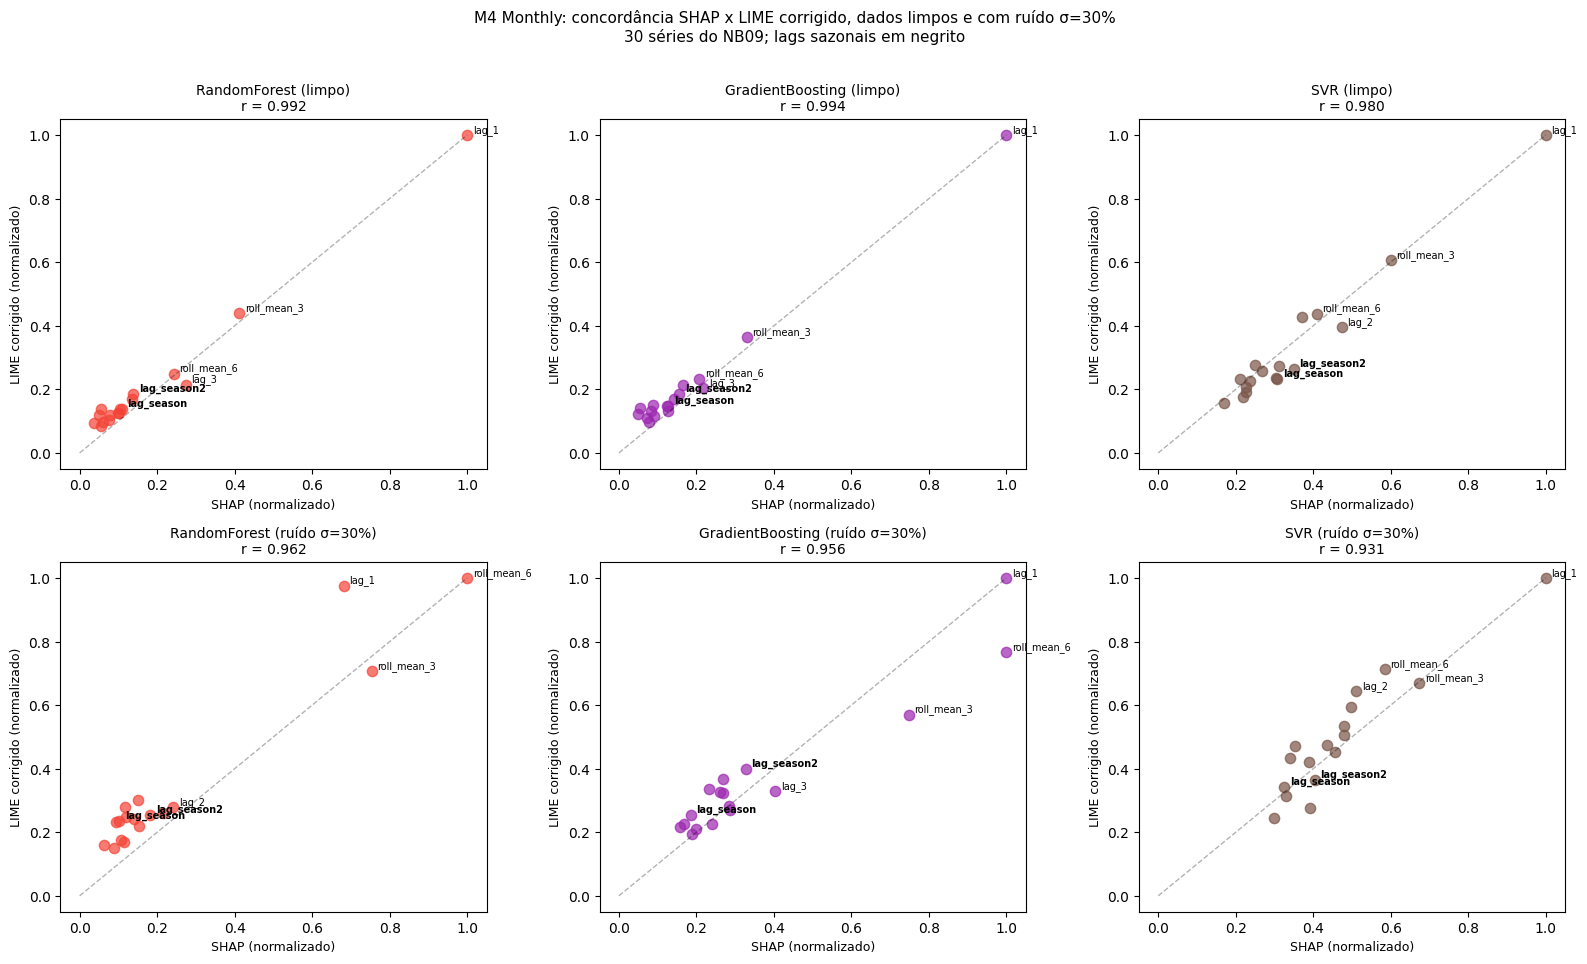

Figura salva: fig_xai_m4_shap_vs_lime_corrigido.png


In [18]:
# ── Figura: SHAP x LIME corrigido (normalizados), limpo e com ruído ───────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for lin, (cond, df_s, df_l) in enumerate([('limpo', xai_m4_shap_clean, xai_m4_lime_clean),
                                           ('ruído σ=30%', xai_m4_shap_pert, xai_m4_lime_pert)]):
    for ax, mn in zip(axes[lin], MODELOS_XAI):
        s = df_s[df_s['modelo'] == mn][FEATURE_NAMES].mean(); s = s / (s.max() + 1e-10)
        l = df_l[df_l['modelo'] == mn][FEATURE_NAMES].mean(); l = l / (l.max() + 1e-10)
        r = np.corrcoef(s.values, l.values)[0, 1]
        ax.scatter(s.values, l.values, color=ALGO_COLORS_XAI[mn], alpha=0.7, s=55)
        for fn in set(s.sort_values(ascending=False).index[:4]) | {'lag_season', 'lag_season2'}:
            ax.annotate(fn, (s[fn], l[fn]), fontsize=7, xytext=(4, 2), textcoords='offset points',
                        fontweight='bold' if 'season' in fn else 'normal')
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=1)
        ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
        ax.set_title(f'{mn} ({cond})\nr = {r:.3f}', fontsize=10)
        ax.set_xlabel('SHAP (normalizado)', fontsize=9); ax.set_ylabel('LIME corrigido (normalizado)', fontsize=9)
fig.suptitle('M4 Monthly: concordância SHAP x LIME corrigido, dados limpos e com ruído σ=30%\n'
             '30 séries do NB09; lags sazonais em negrito', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_xai_m4_shap_vs_lime_corrigido.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_xai_m4_shap_vs_lime_corrigido.png')